# Proyek Analisis Data: Bike Sharing Dataset (Capital Bikeshare, Washington D.C.)
- **Nama:** Dimas Elang Satria
- **Email:** dimasbelajar976@gmail.com
- **ID Dicoding:** ds269b6y0459

**Ringkasan proyek.** Proyek ini menganalisis data penyewaan sepeda Capital Bikeshare tahun 2011–2012 (`day.csv` = 731 hari, `hour.csv` = 17.379 jam). Tujuannya adalah membantu operator sistem bike sharing mengambil keputusan operasional (distribusi sepeda, jadwal perawatan, dan promosi) berdasarkan pola waktu, cuaca, musim, dan pertumbuhan penyewaan.

## Menentukan Pertanyaan Bisnis

Ketiga pertanyaan disusun dengan kerangka **SMART**.

1. **Pertanyaan 1:** Pada jam berapa rata-rata penyewaan sepeda per jam mencapai puncak tertinggi pada hari kerja dibandingkan akhir pekan/libur selama periode 2011–2012?
2. **Pertanyaan 2:** Berapa persen penurunan rata-rata penyewaan harian saat cuaca hujan/salju ringan dibandingkan cuaca cerah selama periode 2011–2012?
3. **Pertanyaan 3:** Berapa persen pertumbuhan total penyewaan sepeda tahun 2012 dibandingkan tahun 2011 (Year-over-Year)?

| Elemen SMART | Penjelasan |
|---|---|
| Specific | Satu fokus per pertanyaan: jam puncak (P1), dampak cuaca hujan/salju ringan (P2), pertumbuhan tahunan (P3) pada sistem Capital Bikeshare |
| Measurable | Jam dengan rata-rata penyewaan tertinggi, persentase penurunan, persentase pertumbuhan YoY |
| Action-oriented | P1: jadwal redistribusi sepeda dan perawatan. P2: penyesuaian armada saat cuaca buruk. P3: perencanaan kapasitas armada |
| Relevant | Ketersediaan sepeda pada waktu dan kondisi yang tepat adalah masalah inti operator bike sharing |
| Time-bound | Periode 1 Januari 2011 – 31 Desember 2012 |


## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mtick

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.labelsize": 11,
})
# Palet konsisten: biru = fokus utama, abu-abu = pembanding, oranye = sorotan
BLUE, GREY, ORANGE = "#1f6fb2", "#b8bfc7", "#e8833a"

## Data Wrangling

### Gathering Data

Dua berkas dimuat ke DataFrame: `day.csv` (agregasi harian) dan `hour.csv` (agregasi per jam). Keduanya memiliki kolom yang sama, hanya `hour.csv` memiliki kolom tambahan `hr`.

In [2]:
day_df = pd.read_csv("data/day.csv")
hour_df = pd.read_csv("data/hour.csv")
print("day.csv :", day_df.shape)
print("hour.csv:", hour_df.shape)
day_df.head()

day.csv : (731, 16)
hour.csv: (17379, 17)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight (Gathering Data)**
- `day.csv` berisi 731 baris (2011–2012, tahun 2012 kabisat) dan `hour.csv` berisi 17.379 baris.
- Jika setiap jam terisi penuh, seharusnya ada 731 × 24 = **17.544** baris per jam. Selisih 165 baris menjadi petunjuk awal adanya jam yang tidak tercatat. Hal ini diperiksa di tahap *assessing*.

### Assessing Data

In [4]:
for name, df in [("day_df", day_df), ("hour_df", hour_df)]:
    print(f"===== {name} =====")
    df.info()
    print("Missing value total :", df.isna().sum().sum())
    print("Duplikat            :", df.duplicated().sum())
    print()

===== day_df =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB
Missing value total : 0
Duplikat            : 0

===== hour_df =====
<clas

In [5]:
# 1) Konsistensi: cnt harus = casual + registered
for name, df in [("day_df", day_df), ("hour_df", hour_df)]:
    print(name, "| baris cnt != casual+registered:", (df["cnt"] != df["casual"] + df["registered"]).sum())

# 2) Nilai tidak valid: kelembapan (hum) = 0 secara fisik tidak masuk akal
print("\nday_df  hum == 0 :", (day_df["hum"] == 0).sum(), "baris ->", day_df.loc[day_df["hum"] == 0, "dteday"].tolist())
print("hour_df hum == 0 :", (hour_df["hum"] == 0).sum(), "baris -> tanggal:", hour_df.loc[hour_df["hum"] == 0, "dteday"].unique().tolist())

# 3) windspeed = 0
print("\nhour_df windspeed == 0:", (hour_df["windspeed"] == 0).sum(), f"({(hour_df['windspeed']==0).mean():.1%} baris)")

# 4) Tipe data tanggal
print("\nTipe dteday:", day_df["dteday"].dtype)

# 5) Jam yang hilang pada hour_df
full_hours = 731 * 24
print(f"\nJam hilang pada hour_df: {full_hours} - {len(hour_df)} = {full_hours - len(hour_df)}")
print("Jumlah hari dengan data < 24 jam:", (hour_df.groupby('dteday').size() < 24).sum())

# 6) Cek weathersit
print("\nSebaran weathersit (hour):\n", hour_df["weathersit"].value_counts().sort_index())

day_df | baris cnt != casual+registered: 0
hour_df | baris cnt != casual+registered: 0

day_df  hum == 0 : 1 baris -> ['2011-03-10']
hour_df hum == 0 : 22 baris -> tanggal: ['2011-03-10']

hour_df windspeed == 0: 2180 (12.5% baris)

Tipe dteday: object

Jam hilang pada hour_df: 17544 - 17379 = 165
Jumlah hari dengan data < 24 jam: 76

Sebaran weathersit (hour):
 weathersit
1    11413
2     4544
3     1419
4        3
Name: count, dtype: int64


In [6]:
# 7) Outlier (metode IQR) pada cnt harian dan per jam
def iqr_outlier(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

print("Outlier cnt harian  :", iqr_outlier(day_df["cnt"]))
print("Outlier casual harian:", iqr_outlier(day_df["casual"]))
print("Outlier cnt per jam :", iqr_outlier(hour_df["cnt"]), f"({iqr_outlier(hour_df['cnt'])/len(hour_df):.1%})")
print()
print(day_df.nsmallest(3, "cnt")[["dteday", "cnt", "weathersit"]])

Outlier cnt harian  : 0
Outlier casual harian: 44
Outlier cnt per jam : 505 (2.9%)

         dteday  cnt  weathersit
667  2012-10-29   22           3
26   2011-01-27  431           1
725  2012-12-26  441           3


**Insight (Assessing Data)** — masalah yang ditemukan dan tindakan pada tahap *cleaning*:

| # | Jenis masalah | Temuan | Solusi |
|---|---|---|---|
| 1 | **Invalid value** | `hum = 0` pada 1 hari di `day.csv` (2011-03-10) dan 22 jam di `hour.csv` pada tanggal yang sama. Kelembapan 0% tidak mungkin terjadi. | Ubah menjadi `NaN`, lalu isi dengan median kelembapan bulan yang sama. |
| 2 | **Missing value tersembunyi (jam hilang)** | `hour.csv` kehilangan 165 baris jam. Jam tanpa penyewaan tidak dicatat, sehingga rata-rata per jam berpotensi *terlalu tinggi*. | Buat grid lengkap tanggal × jam, lalu isi jumlah penyewaan jam yang hilang dengan 0 dan lengkapi atribut cuaca dari jam terdekat. |
| 3 | **Inaccurate/inconsistent value** | `dteday` bertipe *string*. Kolom `season`, `weathersit`, `weekday`, `yr`, `mnth` berupa kode angka. `temp`, `atemp`, `hum`, `windspeed` masih ternormalisasi. | Ubah ke `datetime`, beri label deskriptif, dan kembalikan suhu/kelembapan/kecepatan angin ke satuan aslinya. |
| 4 | **Outlier** | Terdapat outlier pada `casual` harian dan `cnt` per jam. Nilai terendah adalah **2012-10-29 (cnt = 22)**, bertepatan dengan Badai Sandy. | **Dipertahankan** karena bukan *error*: hari puncak dan hari badai adalah perilaku nyata sistem. |
| 5 | **Inaccurate value (catatan)** | `windspeed = 0` pada ~12,5% jam, kemungkinan alat ukur tidak mencatat. | Tidak diubah karena `windspeed` bukan variabel utama. Hanya dicatat sebagai keterbatasan. |

Tidak ada *missing value* eksplisit maupun data duplikat, dan `cnt = casual + registered` konsisten.

### Cleaning Data

**Langkah 1 — Tipe data, label kategori, dan denormalisasi satuan (`day_df`).** Faktor normalisasi mengikuti Readme: suhu ÷ 41, suhu terasa ÷ 50, kelembapan ÷ 100, kecepatan angin ÷ 67.

In [7]:
season_map  = {1: "Semi", 2: "Panas", 3: "Gugur", 4: "Dingin"}   # springer, summer, fall, winter
weather_map = {1: "Cerah", 2: "Berkabut/Berawan", 3: "Hujan/Salju Ringan", 4: "Hujan/Salju Lebat"}
weekday_map = {0: "Minggu", 1: "Senin", 2: "Selasa", 3: "Rabu", 4: "Kamis", 5: "Jumat", 6: "Sabtu"}
month_map   = {1:"Jan",2:"Feb",3:"Mar",4:"Apr",5:"Mei",6:"Jun",7:"Jul",8:"Agu",9:"Sep",10:"Okt",11:"Nov",12:"Des"}

def clean_common(df):
    df = df.copy()
    df["dteday"] = pd.to_datetime(df["dteday"])
    # 1) hum = 0 -> NaN -> median kelembapan bulan yang sama (hanya nilai valid)
    df["hum"] = df["hum"].replace(0, np.nan)
    med = df.groupby(["yr", "mnth"])["hum"].transform("median")
    df["hum"] = df["hum"].fillna(med)
    # 2) denormalisasi
    df["temp_c"]    = df["temp"] * 41
    df["atemp_c"]   = df["atemp"] * 50
    df["hum_pct"]   = df["hum"] * 100
    df["wind_kmh"]  = df["windspeed"] * 67
    # 3) label kategori
    df["year"]        = df["yr"].map({0: 2011, 1: 2012})
    df["season_lbl"]  = df["season"].map(season_map)
    df["weather_lbl"] = df["weathersit"].map(weather_map)
    df["weekday_lbl"] = df["weekday"].map(weekday_map)
    df["month_lbl"]   = df["mnth"].map(month_map)
    df["day_type"]    = np.where(df["workingday"] == 1, "Hari Kerja", "Akhir Pekan/Libur")
    return df

day_clean = clean_common(day_df)
print("hum == 0 setelah cleaning:", (day_clean["hum_pct"] == 0).sum())
day_clean.loc[day_clean["dteday"] == "2011-03-10", ["dteday", "hum", "hum_pct"]]

hum == 0 setelah cleaning: 0


,dteday,hum,hum_pct
68,2011-03-10,0.572944,57.29435


**Langkah 2 — Melengkapi jam yang hilang pada `hour_df`.** Setiap kombinasi tanggal × jam dibuat lengkap (17.544 baris). Baris yang sebelumnya tidak ada diberi penyewaan 0. Atribut kalender diambil dari `day.csv`, sedangkan atribut cuaca diisi dari jam terdekat pada urutan waktu.

In [8]:
grid = pd.MultiIndex.from_product(
    [pd.date_range("2011-01-01", "2012-12-31"), range(24)], names=["dteday", "hr"]
).to_frame(index=False)

hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])
hour_full = grid.merge(hour_df.drop(columns=["instant"]), on=["dteday", "hr"], how="left")
hour_full["is_imputed_hour"] = hour_full["cnt"].isna()

# atribut kalender dari day.csv
cal_cols = ["season", "yr", "mnth", "holiday", "weekday", "workingday"]
cal = day_df.assign(dteday=pd.to_datetime(day_df["dteday"]))[["dteday"] + cal_cols]
hour_full = hour_full.drop(columns=cal_cols).merge(cal, on="dteday", how="left")

# jumlah penyewaan: jam tidak tercatat = 0 penyewaan
for c in ["casual", "registered", "cnt"]:
    hour_full[c] = hour_full[c].fillna(0).astype(int)

# atribut cuaca: isi dari jam terdekat
weather_cols = ["weathersit", "temp", "atemp", "hum", "windspeed"]
hour_full[weather_cols] = hour_full[weather_cols].ffill().bfill()
hour_full["weathersit"] = hour_full["weathersit"].astype(int)

hour_clean = clean_common(hour_full)
print("Baris hour_clean :", len(hour_clean), "| jam hasil imputasi:", hour_clean["is_imputed_hour"].sum())
print("Missing value    :", hour_clean.isna().sum().sum())
print("hum == 0         :", (hour_clean["hum_pct"] == 0).sum())
print("cnt = casual+reg :", (hour_clean["cnt"] == hour_clean["casual"] + hour_clean["registered"]).all())

Baris hour_clean : 17544 | jam hasil imputasi: 165
Missing value    : 0
hum == 0         : 0
cnt = casual+reg : True


**Langkah 3 — Pengelompokan lanjutan (manual grouping & binning)**, dipakai sebagai teknik analisis lanjutan tanpa *machine learning*:
- **Segmen waktu (manual grouping)** dari jam: Dini Hari (00–05), Pagi (06–09), Siang (10–15), Sore (16–19), Malam (20–23). Batas ini sesuai jam sibuk komuter dan dipakai untuk membaca pola permintaan secara ringkas.
- **Kategori suhu (binning dengan `pd.cut`)** pada suhu asli (°C): Dingin (<10), Sejuk (10–20), Hangat (20–30), Panas (>30). Tujuannya melihat rentang suhu yang optimal untuk bersepeda.
- **Tingkat permintaan harian (binning berbasis kuantil dengan `pd.qcut`)**: Rendah, Sedang, Tinggi (masing-masing ±33% hari). Tujuannya mengelompokkan hari menurut volume penyewaan untuk perencanaan armada.

In [9]:
time_bins   = [-1, 5, 9, 15, 19, 23]
time_labels = ["Dini Hari (00-05)", "Pagi (06-09)", "Siang (10-15)", "Sore (16-19)", "Malam (20-23)"]
hour_clean["time_segment"] = pd.cut(hour_clean["hr"], bins=time_bins, labels=time_labels)

temp_bins   = [-np.inf, 10, 20, 30, np.inf]
temp_labels = ["Dingin (<10°C)", "Sejuk (10-20°C)", "Hangat (20-30°C)", "Panas (>30°C)"]
day_clean["temp_category"] = pd.cut(day_clean["temp_c"], bins=temp_bins, labels=temp_labels, right=False)

day_clean["demand_level"] = pd.qcut(day_clean["cnt"], q=3, labels=["Rendah", "Sedang", "Tinggi"])

print(day_clean["temp_category"].value_counts().sort_index())
print()
print(day_clean.groupby("demand_level", observed=True)["cnt"].agg(["min", "max", "count"]))

temp_category
Dingin (<10°C)       60
Sejuk (10-20°C)     299
Hangat (20-30°C)    300
Panas (>30°C)        72
Name: count, dtype: int64

               min   max  count
demand_level                   
Rendah          22  3740    244
Sedang        3744  5312    244
Tinggi        5315  8714    243


In [10]:
# Simpan data bersih untuk dashboard
day_clean.to_csv("dashboard/day_data.csv", index=False)
hour_clean.to_csv("dashboard/main_data.csv", index=False)
print("Tersimpan: dashboard/main_data.csv (per jam) & dashboard/day_data.csv (harian)")

Tersimpan: dashboard/main_data.csv (per jam) & dashboard/day_data.csv (harian)


**Insight (Cleaning Data)**
- Semua masalah dari tahap *assessing* sudah ditangani: kelembapan tidak valid diperbaiki, 165 jam hilang dilengkapi (`is_imputed_hour` menandai barisnya), dan kolom kategorikal serta satuan sudah mudah dibaca.
- Outlier sengaja dipertahankan agar peristiwa nyata (misalnya Badai Sandy) tetap terlihat.
- Data bersih disimpan sebagai `main_data.csv` (per jam) dan `day_data.csv` (harian) untuk dashboard Streamlit.

## Exploratory Data Analysis (EDA)

### Eksplorasi umum

In [11]:
day_clean[["cnt", "casual", "registered", "temp_c", "hum_pct", "wind_kmh"]].describe().round(1)

,cnt,casual,registered,temp_c,hum_pct,wind_kmh
count,731.0,731.0,731.0,731.0,731.0,731.0
mean,4504.3,848.2,3656.2,20.3,62.9,12.8
std,1937.2,686.6,1560.3,7.5,14.1,5.2
min,22.0,2.0,20.0,2.4,18.8,1.5
25%,3152.0,315.5,2497.0,13.8,52.1,9.0
50%,4548.0,713.0,3662.0,20.4,62.7,12.1
75%,5956.0,1096.0,4776.5,26.9,73.0,15.6
max,8714.0,3410.0,6946.0,35.3,97.2,34.0


In [12]:
total = day_clean[["casual", "registered", "cnt"]].sum()
print("Total penyewaan 2011-2012 :", f"{total['cnt']:,}")
print(f"Porsi registered          : {total['registered']/total['cnt']:.1%}")
print(f"Porsi casual              : {total['casual']/total['cnt']:.1%}")
print()
print(day_clean.groupby("year")["cnt"].agg(["sum", "mean"]).round(0))
print()
# korelasi cnt dengan variabel cuaca
day_clean[["cnt", "temp_c", "atemp_c", "hum_pct", "wind_kmh"]].corr()["cnt"].round(2)

Total penyewaan 2011-2012 : 3,292,679
Porsi registered          : 81.2%
Porsi casual              : 18.8%

          sum    mean
year                 
2011  1243103  3406.0
2012  2049576  5600.0



cnt         1.00
temp_c      0.63
atemp_c     0.63
hum_pct    -0.11
wind_kmh   -0.23
Name: cnt, dtype: float64

**Insight (EDA umum)**
- Rata-rata penyewaan harian sekitar 4.500, dengan sebaran lebar (22 hingga 8.714). Artinya permintaan sangat dipengaruhi faktor eksternal.
- Pengguna **registered** mendominasi (sekitar 81%), sedangkan *casual* sekitar 19%.
- Suhu berkorelasi positif cukup kuat dengan penyewaan (≈ 0,63). Kelembapan dan kecepatan angin berkorelasi negatif lemah.

### Pertanyaan 1 — Pola penyewaan per jam: hari kerja vs akhir pekan/libur

In [13]:
hourly = (hour_clean.groupby(["day_type", "hr"])[["cnt", "casual", "registered"]].mean().round(1).reset_index())
pivot_cnt = hourly.pivot(index="hr", columns="day_type", values="cnt")
pivot_cnt.T.round(0).astype(int)

hr,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
day_type,,,,,,,,,,,,,,,,,,,,,
Akhir Pekan/Libur,90,69,52,25,8,8,19,43,106,172,...,365,359,353,324,280,231,174,141,116,86
Hari Kerja,36,16,8,5,5,25,102,288,473,240,...,183,200,292,524,490,347,249,186,138,88


In [14]:
for t in ["Hari Kerja", "Akhir Pekan/Libur"]:
    sub = hourly[hourly["day_type"] == t].sort_values("cnt", ascending=False)
    print(f"== {t} ==  3 jam teratas")
    print(sub.head(3)[["hr", "cnt", "casual", "registered"]].to_string(index=False))
    top = sub.iloc[0]
    print(f"   porsi casual di jam puncak: {top['casual']/top['cnt']:.1%}\n")

seg = (hour_clean.groupby(["day_type", "time_segment"], observed=True)["cnt"].mean().round(1).unstack(0))
seg

== Hari Kerja ==  3 jam teratas
 hr   cnt  casual  registered
 17 524.2    56.8       467.5
 18 490.3    50.2       440.0
  8 473.2    22.1       451.1
   porsi casual di jam puncak: 10.8%

== Akhir Pekan/Libur ==  3 jam teratas
 hr   cnt  casual  registered
 13 372.7   136.4       236.3
 12 366.3   126.2       240.0
 14 364.6   139.6       225.1
   porsi casual di jam puncak: 36.6%



day_type,Akhir Pekan/Libur,Hari Kerja
time_segment,,
Dini Hari (00-05),42.3,16.0
Pagi (06-09),84.8,275.7
Siang (10-15),338.9,178.6
Sore (16-19),296.7,413.5
Malam (20-23),129.1,165.1


In [15]:
share = hour_clean.groupby("day_type")[["casual", "registered"]].sum()
share["casual_pct"] = (share["casual"] / (share["casual"] + share["registered"]) * 100).round(1)
share

,casual,registered,casual_pct
day_type,,,
Akhir Pekan/Libur,316732,683537,31.7
Hari Kerja,303285,1989125,13.2


**Insight (EDA Pertanyaan 1)**
- **Hari kerja** memiliki **dua puncak komuter**: pagi sekitar **jam 08:00** (±473 sewa/jam) dan sore sekitar **jam 17:00** (puncak tertinggi, ±524 sewa/jam), dengan lembah di tengah hari.
- **Akhir pekan/libur** memiliki **satu puncak lebar siang hari** (sekitar jam 12:00–15:00, ±370 sewa/jam) dan hampir tidak ada lonjakan komuter.
- Porsi *casual* jauh lebih besar saat akhir pekan/libur (sekitar 32%) dibanding hari kerja (sekitar 13%), sehingga akhir pekan didominasi pengguna rekreasi.

### Pertanyaan 2 — Penurunan penyewaan saat hujan/salju ringan (didukung analisis musim dan suhu)

In [16]:
w = day_clean.groupby("weather_lbl")["cnt"].agg(["mean", "count"]).round(0)
w = w.reindex(["Cerah", "Berkabut/Berawan", "Hujan/Salju Ringan"])
w["selisih_vs_cerah_%"] = ((w["mean"] / w.loc["Cerah", "mean"] - 1) * 100).round(1)
w

,mean,count,selisih_vs_cerah_%
weather_lbl,,,
Cerah,4877.0,463,0.0
Berkabut/Berawan,4036.0,247,-17.2
Hujan/Salju Ringan,1803.0,21,-63.0


In [17]:
s = day_clean.groupby("season_lbl")["cnt"].mean().round(0).reindex(["Semi", "Panas", "Gugur", "Dingin"])
temp_tbl = day_clean.groupby("temp_category", observed=True)["cnt"].agg(["mean", "count"]).round(0)
print(s, "\n"); print(temp_tbl)

season_lbl
Semi      2604.0
Panas     4992.0
Gugur     5644.0
Dingin    4728.0
Name: cnt, dtype: float64 

                    mean  count
temp_category                  
Dingin (<10°C)    1678.0     60
Sejuk (10-20°C)   3692.0    299
Hangat (20-30°C)  5662.0    300
Panas (>30°C)     5410.0     72


In [18]:
pd.crosstab(day_clean["season_lbl"], day_clean["weather_lbl"], normalize="index").mul(100).round(1)

weather_lbl,Berkabut/Berawan,Cerah,Hujan/Salju Ringan
season_lbl,,,
Dingin,36.5,57.9,5.6
Gugur,25.5,72.3,2.1
Panas,37.0,61.4,1.6
Semi,36.5,61.3,2.2


**Insight (EDA Pertanyaan 2)**
- Rata-rata penyewaan harian: **cerah ≈ 4.877**, **berkabut/berawan ≈ 4.036**, **hujan/salju ringan ≈ 1.803**. Cuaca buruk menurunkan penyewaan sekitar **63%** dibanding cuaca cerah.
- Musim **Gugur** tertinggi (≈ 5.644), disusul **Panas** (≈ 4.992) dan **Dingin** (≈ 4.728). Musim **Semi** terendah (≈ 2.604).
- Berdasarkan suhu, kategori **Hangat (20–30°C)** tertinggi (≈ 5.662), disusul Panas (≈ 5.410). Suhu **Dingin (<10°C)** hanya ≈ 1.678, sehingga suhu optimal ada pada 20–30°C dan penyewaan menurun di suhu ekstrem.
- Catatan: kategori cuaca 4 (lebat) hanya muncul 3 jam sehingga tidak dibahas pada level harian.

### Pertanyaan 3 — Pertumbuhan total penyewaan 2012 vs 2011 (YoY)

In [19]:
yearly = day_clean.groupby("year")["cnt"].sum()
print(yearly, f"\nPertumbuhan YoY: {yearly[2012]/yearly[2011]-1:.1%}")

monthly = day_clean.pivot_table(index="mnth", columns="year", values="cnt", aggfunc="sum")
monthly["yoy_%"] = ((monthly[2012] / monthly[2011] - 1) * 100).round(1)
monthly.index = [month_map[i] for i in monthly.index]
monthly

year
2011    1243103
2012    2049576
Name: cnt, dtype: int64 
Pertumbuhan YoY: 64.9%


year,2011,2012,yoy_%
Jan,38189,96744,153.3
Feb,48215,103137,113.9
Mar,64045,164875,157.4
Apr,94870,174224,83.6
Mei,135821,195865,44.2
Jun,143512,202830,41.3
Jul,141341,203607,44.1
Agu,136691,214503,56.9
Sep,127418,218573,71.5
Okt,123511,198841,61.0


In [20]:
print("Bulan puncak 2011:", monthly[2011].idxmax(), "| 2012:", monthly[2012].idxmax())
print("Bulan YoY terendah:", monthly["yoy_%"].idxmin(), monthly["yoy_%"].min(), "%")
print("Bulan YoY tertinggi:", monthly["yoy_%"].idxmax(), monthly["yoy_%"].max(), "%")
# pertumbuhan per tipe pengguna
print(day_clean.groupby("year")[["casual", "registered"]].sum().pct_change().iloc[-1].mul(100).round(1))

Bulan puncak 2011: Jun | 2012: Sep
Bulan YoY terendah: Jun 41.3 %
Bulan YoY tertinggi: Mar 157.4 %
casual        50.8
registered    68.4
Name: 2012, dtype: float64


**Insight (EDA Pertanyaan 3)**
- Total penyewaan naik dari ±1,24 juta (2011) menjadi ±2,05 juta (2012), yakni **tumbuh sekitar 64,9%**.
- Pertumbuhan tertinggi terjadi di awal tahun (Jan–Mar), karena basis 2011 masih kecil saat sistem baru berkembang. Pertumbuhan terendah di pertengahan tahun, yaitu **Juni (+41%)** dan **Desember (+42%)**.
- Puncak bulanan 2011 jatuh pada **Juni** (≈ 143 ribu), sedangkan puncak 2012 pada **September** (≈ 219 ribu).

## Visualization & Explanatory Analysis

### Pertanyaan 1: Pada jam berapa penyewaan memuncak pada hari kerja vs akhir pekan/libur?

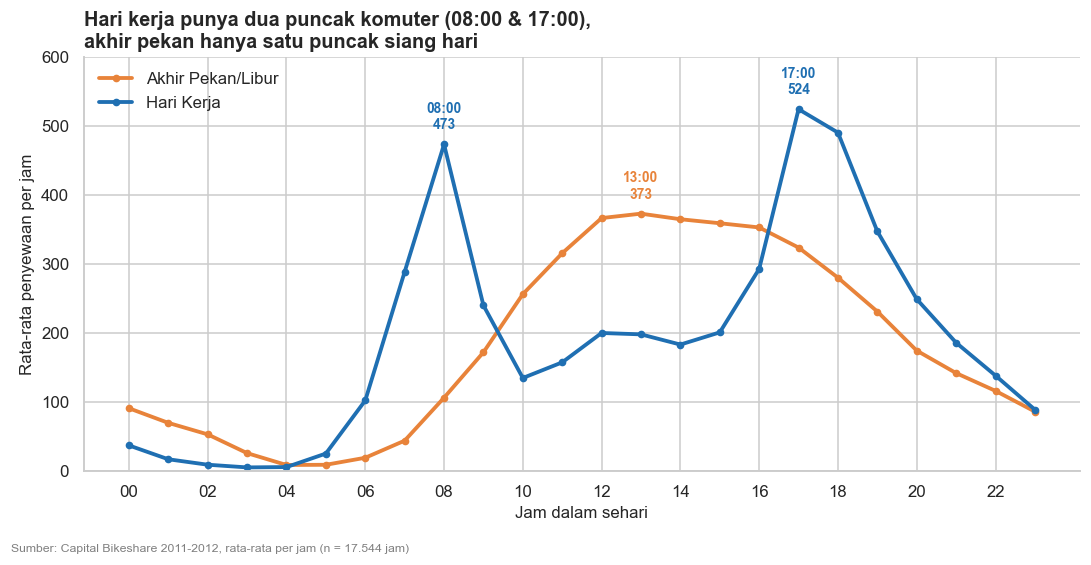

In [21]:
fig, ax = plt.subplots(figsize=(10, 5))
colors = {"Hari Kerja": BLUE, "Akhir Pekan/Libur": ORANGE}
for t, g in hourly.groupby("day_type"):
    ax.plot(g["hr"], g["cnt"], color=colors[t], lw=2.5, marker="o", ms=4, label=t)

wk = hourly[hourly["day_type"] == "Hari Kerja"].set_index("hr")["cnt"]
we = hourly[hourly["day_type"] != "Hari Kerja"].set_index("hr")["cnt"]
for h_, v in [(8, wk[8]), (17, wk[17])]:
    ax.annotate(f"{h_:02d}:00\n{v:.0f}", (h_, v), textcoords="offset points", xytext=(0, 10), ha="center", color=BLUE, fontweight="bold", fontsize=9)
pk = we.idxmax()
ax.annotate(f"{pk:02d}:00\n{we[pk]:.0f}", (pk, we[pk]), textcoords="offset points", xytext=(0, 10), ha="center", color=ORANGE, fontweight="bold", fontsize=9)

ax.set_xticks(range(0, 24, 2)); ax.set_xticklabels([f"{h:02d}" for h in range(0, 24, 2)])
ax.set_xlabel("Jam dalam sehari"); ax.set_ylabel("Rata-rata penyewaan per jam")
ax.set_ylim(0, 600)
ax.set_title("Hari kerja punya dua puncak komuter (08:00 & 17:00),\nakhir pekan hanya satu puncak siang hari", loc="left")
ax.legend(frameon=False, loc="upper left")
fig.text(0.01, -0.02, "Sumber: Capital Bikeshare 2011-2012, rata-rata per jam (n = 17.544 jam)", fontsize=8, color="grey")
plt.tight_layout(); plt.show()

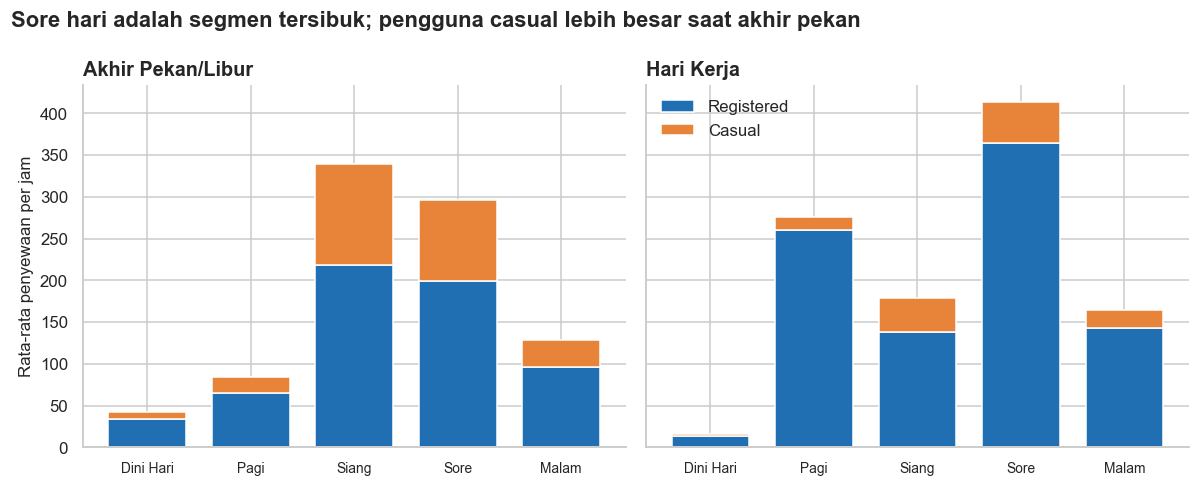

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
order = time_labels
for ax, (t, g) in zip(axes, hour_clean.groupby("day_type")):
    m = g.groupby("time_segment", observed=True)[["registered", "casual"]].mean().reindex(order)
    m.plot(kind="bar", stacked=True, ax=ax, color=[BLUE, ORANGE], width=0.75, legend=False)
    ax.set_title(t, loc="left"); ax.set_xlabel(""); ax.set_xticklabels([l.split(" (")[0] for l in order], rotation=0, fontsize=9)
axes[0].set_ylabel("Rata-rata penyewaan per jam")
axes[1].legend(["Registered", "Casual"], frameon=False)
fig.suptitle("Sore hari adalah segmen tersibuk; pengguna casual lebih besar saat akhir pekan", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

**Penjelasan.** Pada hari kerja, kurva berbentuk dua puncak yang selaras dengan jam berangkat dan pulang kerja. Pada akhir pekan/libur, kurva berbentuk satu puncak lebar di siang hari. Grafik kedua menunjukkan segmen **Sore (16–19)** paling sibuk pada hari kerja, sedangkan pada akhir pekan permintaan merata di **Siang–Sore** dengan kontribusi *casual* yang lebih besar.

### Pertanyaan 2: Berapa persen penurunan penyewaan saat hujan/salju ringan? (didukung analisis musim dan suhu)

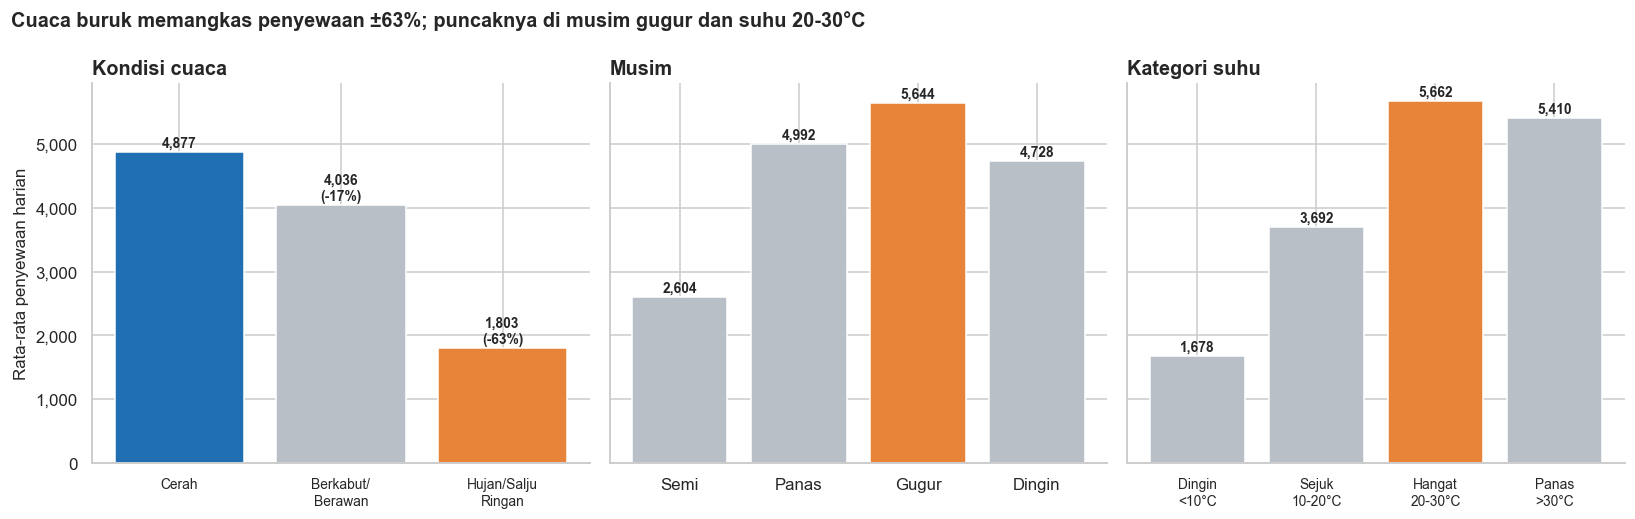

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)

# (a) cuaca
wp = w.reset_index()
bars = axes[0].bar(wp["weather_lbl"], wp["mean"], color=[BLUE, GREY, ORANGE])
for b, v, d in zip(bars, wp["mean"], wp["selisih_vs_cerah_%"]):
    lbl = f"{v:,.0f}" + ("" if d == 0 else f"\n({d:+.0f}%)")
    axes[0].text(b.get_x() + b.get_width()/2, v + 80, lbl, ha="center", fontsize=9, fontweight="bold")
axes[0].set_title("Kondisi cuaca", loc="left"); axes[0].set_xticks(range(3)); axes[0].set_xticklabels(["Cerah", "Berkabut/\nBerawan", "Hujan/Salju\nRingan"], fontsize=9)
axes[0].set_ylabel("Rata-rata penyewaan harian")

# (b) musim
sp = s.reset_index()
cols = [ORANGE if v == sp["cnt"].max() else GREY for v in sp["cnt"]]
bars = axes[1].bar(sp["season_lbl"], sp["cnt"], color=cols)
for b, v in zip(bars, sp["cnt"]): axes[1].text(b.get_x() + b.get_width()/2, v + 80, f"{v:,.0f}", ha="center", fontsize=9, fontweight="bold")
axes[1].set_title("Musim", loc="left")

# (c) suhu
tp = temp_tbl.reset_index()
cols = [ORANGE if v == tp["mean"].max() else GREY for v in tp["mean"]]
bars = axes[2].bar(range(4), tp["mean"], color=cols)
for b, v in zip(bars, tp["mean"]): axes[2].text(b.get_x() + b.get_width()/2, v + 80, f"{v:,.0f}", ha="center", fontsize=9, fontweight="bold")
axes[2].set_xticks(range(4)); axes[2].set_xticklabels(["Dingin\n<10°C", "Sejuk\n10-20°C", "Hangat\n20-30°C", "Panas\n>30°C"], fontsize=9)
axes[2].set_title("Kategori suhu", loc="left")

for ax in axes: ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
fig.suptitle("Cuaca buruk memangkas penyewaan ±63%; puncaknya di musim gugur dan suhu 20-30°C", x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout(); plt.show()

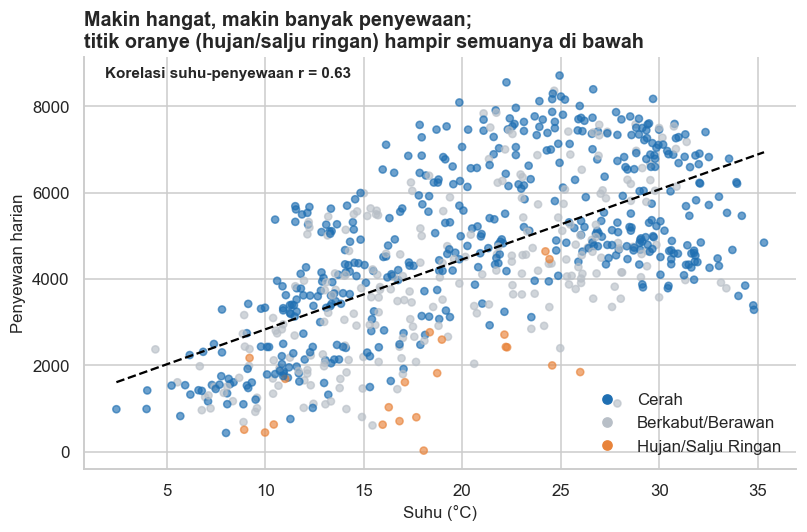

In [24]:
fig, ax = plt.subplots(figsize=(7.5, 5))
sc = ax.scatter(day_clean["temp_c"], day_clean["cnt"], c=day_clean["weathersit"].map({1: BLUE, 2: GREY, 3: ORANGE}), alpha=.65, s=22)
z = np.polyfit(day_clean["temp_c"], day_clean["cnt"], 1)
xs = np.linspace(day_clean["temp_c"].min(), day_clean["temp_c"].max(), 50)
ax.plot(xs, np.polyval(z, xs), color="black", lw=1.5, ls="--")
r = day_clean["temp_c"].corr(day_clean["cnt"])
ax.text(0.03, 0.95, f"Korelasi suhu-penyewaan r = {r:.2f}", transform=ax.transAxes, fontsize=10, fontweight="bold")
ax.set_xlabel("Suhu (°C)"); ax.set_ylabel("Penyewaan harian")
ax.set_title("Makin hangat, makin banyak penyewaan;\ntitik oranye (hujan/salju ringan) hampir semuanya di bawah", loc="left")
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=c, label=l) for c, l in [(BLUE, "Cerah"), (GREY, "Berkabut/Berawan"), (ORANGE, "Hujan/Salju Ringan")]], frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

**Penjelasan.** Hujan/salju ringan menurunkan rata-rata penyewaan harian dari ±4.877 (cerah) menjadi ±1.803. Musim **Gugur** unggul, sedangkan **Semi** terendah, sebagian karena sistem masih tumbuh pada awal 2011. Kategori suhu **Hangat (20–30°C)** memberi rata-rata tertinggi, dan penyewaan turun drastis saat suhu <10°C.

### Pertanyaan 3: Pertumbuhan penyewaan 2012 vs 2011

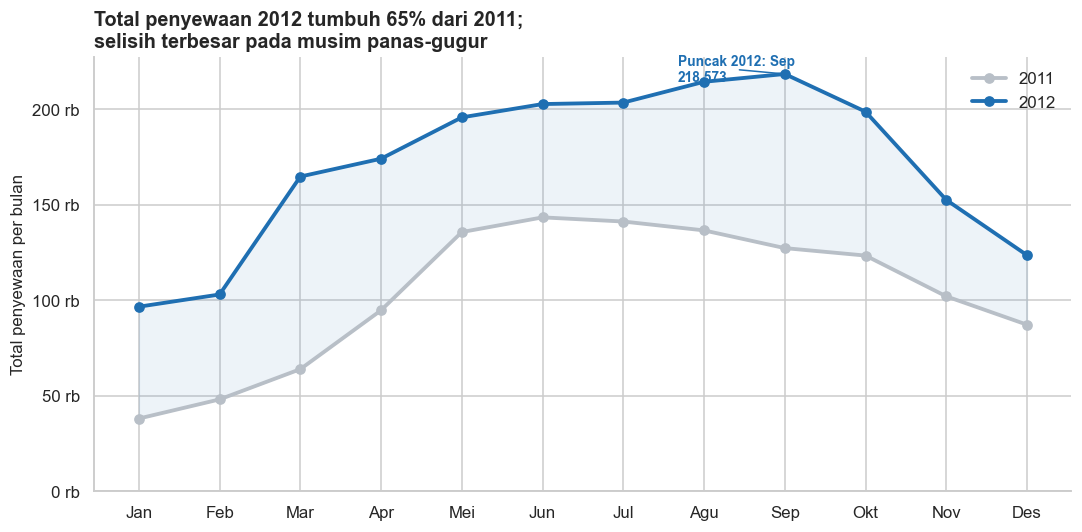

In [25]:
fig, ax = plt.subplots(figsize=(10, 5))
months = list(monthly.index)
ax.plot(months, monthly[2011], color=GREY, lw=2.5, marker="o", label="2011")
ax.plot(months, monthly[2012], color=BLUE, lw=2.5, marker="o", label="2012")
ax.fill_between(months, monthly[2011], monthly[2012], color=BLUE, alpha=.08)
pk = monthly[2012].idxmax()
ax.annotate(f"Puncak 2012: {pk}\n{monthly.loc[pk, 2012]:,.0f}", (pk, monthly.loc[pk, 2012]), xytext=(-70, -5), textcoords="offset points", fontsize=9, fontweight="bold", color=BLUE, arrowprops=dict(arrowstyle="-", color=BLUE))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1000:.0f} rb"))
ax.set_ylabel("Total penyewaan per bulan"); ax.set_ylim(0)
ax.set_title(f"Total penyewaan 2012 tumbuh {yearly[2012]/yearly[2011]-1:.0%} dari 2011;\nselisih terbesar pada musim panas-gugur", loc="left")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

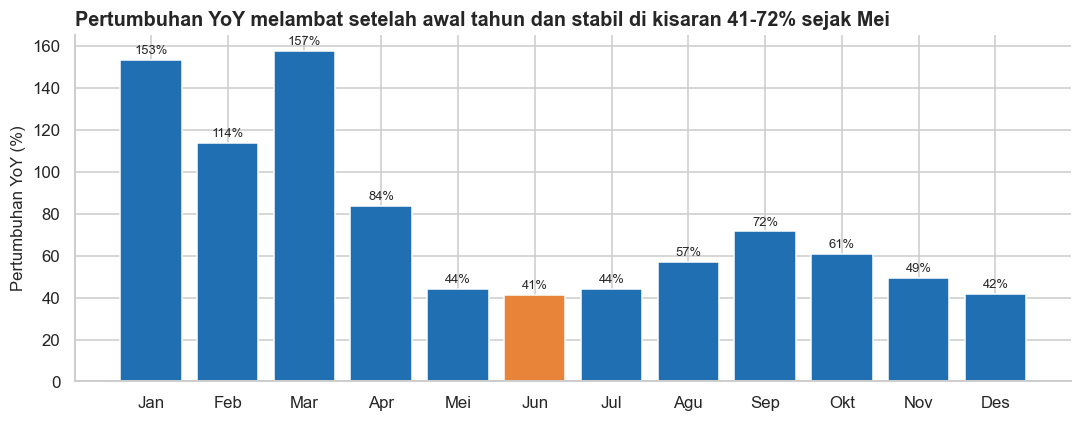

In [26]:
fig, ax = plt.subplots(figsize=(10, 4))
cols = [ORANGE if v == monthly["yoy_%"].min() else BLUE for v in monthly["yoy_%"]]
ax.bar(months, monthly["yoy_%"], color=cols)
for i, v in enumerate(monthly["yoy_%"]): ax.text(i, v + 3, f"{v:.0f}%", ha="center", fontsize=8.5)
ax.set_ylabel("Pertumbuhan YoY (%)"); ax.set_title("Pertumbuhan YoY melambat setelah awal tahun dan stabil di kisaran 41-72% sejak Mei", loc="left")
plt.tight_layout(); plt.show()

**Penjelasan.** Kedua tahun menunjukkan pola musiman yang sama (naik menuju pertengahan tahun, turun di akhir tahun), tetapi seluruh kurva 2012 berada di atas 2011. Pertumbuhan YoY sangat tinggi di awal tahun (basis kecil), lalu stabil di kisaran 41–72% sejak Mei, sehingga pertumbuhan 2012 terjadi merata dan bukan hanya karena satu bulan tertentu.

## Analisis Lanjutan (Manual Grouping & Binning)

**Tujuan.** Menggabungkan dua teknik pengelompokan tanpa *machine learning* untuk menjawab: *kombinasi kondisi apa yang menghasilkan hari dengan permintaan tinggi, dan seberapa besar peluangnya?*
- **Binning suhu** (`pd.cut`) membagi suhu menjadi 4 kategori.
- **Binning kuantil** (`pd.qcut`) membagi hari menjadi permintaan Rendah/Sedang/Tinggi (masing-masing ±33%).
- **Manual grouping** menggabungkan segmen waktu dan tipe hari untuk membaca pola harian.

Hasilnya berupa tabel peluang hari "Tinggi" untuk setiap kombinasi cuaca dan suhu.

In [27]:
prob = pd.crosstab([day_clean["weather_lbl"], day_clean["temp_category"]], day_clean["demand_level"], normalize="index").mul(100).round(0)
prob["jumlah_hari"] = day_clean.groupby(["weather_lbl", "temp_category"], observed=True).size()
prob = prob.dropna()
prob

demand_level                         Rendah  Sedang  Tinggi  jumlah_hari
weather_lbl        temp_category                                        
Berkabut/Berawan   Dingin (<10°C)     100.0     0.0     0.0           21
                   Sejuk (10-20°C)     60.0    27.0    13.0          112
                   Hangat (20-30°C)    15.0    46.0    39.0          106
                   Panas (>30°C)        0.0    38.0    62.0            8
Cerah              Dingin (<10°C)     100.0     0.0     0.0           36
                   Sejuk (10-20°C)     44.0    32.0    23.0          176
                   Hangat (20-30°C)     2.0    39.0    59.0          187
                   Panas (>30°C)        5.0    48.0    47.0           64
Hujan/Salju Ringan Dingin (<10°C)     100.0     0.0     0.0            3
                   Sejuk (10-20°C)    100.0     0.0     0.0           11
                   Hangat (20-30°C)    71.0    29.0     0.0            7

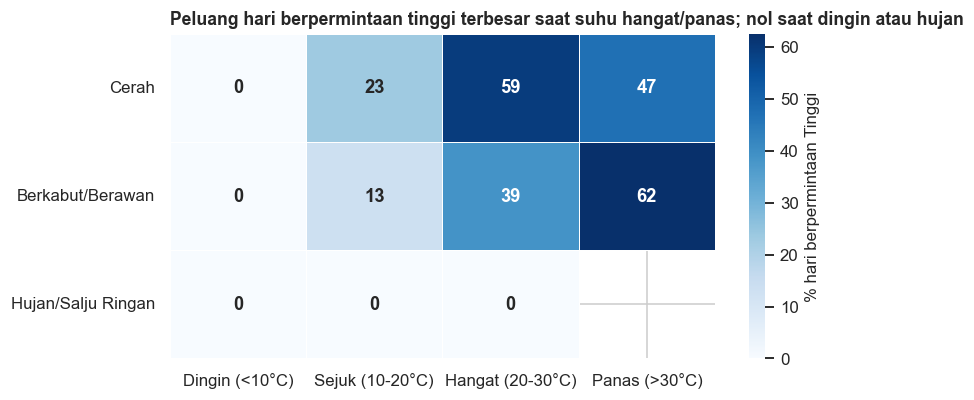

In [28]:
heat = (day_clean[day_clean["weather_lbl"] != "Hujan/Salju Lebat"]
        .assign(high=lambda d: (d["demand_level"] == "Tinggi").astype(int))
        .pivot_table(index="weather_lbl", columns="temp_category", values="high", aggfunc="mean", observed=True).mul(100)
        .reindex(["Cerah", "Berkabut/Berawan", "Hujan/Salju Ringan"]))
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% hari berpermintaan Tinggi"}, ax=ax, linewidths=.5, annot_kws={"fontweight": "bold"})
ax.set_xlabel(""); ax.set_ylabel("")
ax.set_title("Peluang hari berpermintaan tinggi terbesar saat suhu hangat/panas; nol saat dingin atau hujan", loc="left", fontsize=11.5)
plt.tight_layout(); plt.show()

**Insight (Analisis Lanjutan).** Peluang hari berpermintaan **Tinggi** paling besar saat suhu **Hangat/Panas** (sekitar 47–62% pada cuaca cerah atau berkabut). Pada suhu **Dingin** (<10°C) tidak ada satu pun hari yang masuk kategori Tinggi, dan pada cuaca hujan/salju ringan juga tidak ada (0%) meski suhu hangat. Tabel ini bisa menjadi aturan praktis: bila prakiraan cuaca cerah dan 20–30°C, siapkan armada penuh.

## Conclusion

**Kesimpulan Pertanyaan 1 (pola jam).**
- Pada **hari kerja**, penyewaan memuncak dua kali: pagi sekitar **08:00** (±473 sewa/jam) dan sore sekitar **17:00** (±524 sewa/jam), sehingga jam 17:00 adalah puncak tertinggi. Ini pola komuter dan didominasi pengguna *registered* (±87%).
- Pada **akhir pekan/libur**, hanya ada satu puncak lebar di siang hari (sekitar **13:00**, ±373 sewa/jam), dengan porsi *casual* jauh lebih besar (±32% vs ±13% di hari kerja).

**Kesimpulan Pertanyaan 2 (dampak cuaca buruk).**
- Cuaca hujan/salju ringan menurunkan rata-rata penyewaan harian **±63%** (1.803 vs 4.877 saat cerah). Cuaca berkabut/berawan menurunkan ±17%.
- Sebagai konteks tambahan: musim **Gugur** tertinggi (±5.644/hari) dan suhu **Hangat 20–30°C** tertinggi (±5.662/hari). Penyewaan turun tajam di bawah 10°C (±1.678/hari). Suhu berkorelasi positif (r ≈ 0,63) dengan penyewaan.

**Kesimpulan Pertanyaan 3 (pertumbuhan).**
- Total penyewaan 2012 mencapai ±2,05 juta, **tumbuh ±65%** dari 2011 (±1,24 juta). Sejak Mei, pertumbuhan stabil di kisaran 41–72%, dengan puncak bulanan 2012 pada **September** (±219 ribu).

---
### Rekomendasi (Action Items)
1. **Redistribusi sepeda terjadwal pada hari kerja.** Isi stasiun dekat kawasan hunian sebelum 07:00 dan stasiun dekat kawasan perkantoran sebelum 16:00. Pindahkan sepeda kembali pada jam 10:00–15:00 saat permintaan rendah. Gunakan **jendela 00:00–05:00** (rata-rata hari kerja hanya ±16 sewa/jam) untuk perawatan.
2. **Tawarkan paket akhir pekan untuk pengguna *casual*.** Promo seperti *day pass* atau tarif rekreasi pada 11:00–16:00 di Sabtu–Minggu menyasar segmen yang porsinya paling besar di waktu tersebut dan berpotensi mengonversi *casual* menjadi *registered*.
3. **Atur armada berdasarkan prakiraan cuaca.** Jalankan armada penuh saat prakiraan cerah dan 20–30°C. Saat hujan/salju ringan atau suhu <10°C, kurangi sepeda yang dikerahkan sekitar 60% dan pakai waktu itu untuk perawatan. Sediakan promo/insentif saat hujan ringan untuk menahan penurunan.
4. **Rencanakan kapasitas untuk musim gugur dan tren pertumbuhan.** Dengan pertumbuhan ±65% per tahun dan puncak pada Juni–September, tambah armada dan dok sebelum Mei, serta jadwalkan perawatan besar pada Desember–Februari saat permintaan terendah.

**Keterbatasan.** Data hanya mencakup dua tahun, 1 kota, dan variabel cuaca yang diukur harian/jam. Sebagian nilai `windspeed = 0` kemungkinan tidak terukur. Hubungan yang ditemukan bersifat korelasional, bukan kausal.